# Analysis of metagenomic Nanopore sequencing data

We are going to look at data from sequencing 16S rRNA. In the real world, this type of 16S rRNA sequencing would often be done to identify the organisms in a sample of unknown composition, e.g. for diagnostic purposes. Here, we analyze data from a sample of a microbial community that was artificially compiled from eight different organisms: seven bacteria and one yeast.

## Submit your results for grading!

Work on the assignments and answer the questions in this Jupyter notebook. Submit your final notebook with code and produced output **on Moodle** (assignment of the course MDC_53661). Submission due **October 20th, 2026**.


Before submitting:
* run *Kernel → Restart & Run All* and check that all cells run without errors and show their output;
* name the file `MDC53661_<lastnames>_reads<N>.ipynb`, where `N` is the number of your reads file;
* `lastnames` should be the last names of people in your team, separated by '-'.
* upload only the notebook (no data files).

**Work in teams** Work in teams of two or three students! Only one of you should submit on Moodle! Don't forget to put your last names in the file name. Additionally define the list TEAM with your names below.

**Answer format.** Each assignment ends with an *answer cell*: a Python dictionary with fixed keys. Replace every `...` by your answer (numbers, lists, or short text), keep the keys unchanged, and run the cell. You can compute values with code (e.g. `"n_reads": len(data)`). Text answers should be short: at most the number of sentences given in the comment. Your code and plots above the answer cells remain part of the submission.

## Assignments

### Preassignment: Setup 

First, we need to install required bioinformatics software and packages in a conda environment.

From last time, you should have set up your computer appropriately:

* if you have Windows, you can run a PowerShell with WSL  
* you have installed miniforge / miniconda3
* you could run the notebook `computational-setup.ipynb` from the first session

In a terminal or PowerShell after executing wsl, create and activate a conda environment and install software e.g. as follows

```
conda create -n sequencing
conda activate sequencing
conda install jupyter biopython numpy pandas seaborn cd-hit mafft fasttree jalview
```

Note that you need to create the environment and install each package only once, but you need to activate the environment in every session.

Run `jupyter notebook` from the same terminal, where you activated the environment `sequencing`.

Open the url of the jupyter server in a browser or connect Visual Code to the existing server.

If you need more software, it should be installed in the same conda environment.

It should now work to import a series of Python modules as below. Try to get a brief idea of the imported Python packages.

In [25]:
# Biopython
import Bio
from Bio import SeqIO

# some Python standard lib
import random

# Reading compressed data
import gzip

# python modules for data analysis
import numpy as np

# plotting of data
import matplotlib.pyplot as plt
import seaborn as sns

# Answers are printed in a fixed format that is read for grading (do not modify)
import json
def submit(question, answers):
    print(f"#ANSWER {question} " + json.dumps(answers, default=str))

In [26]:
# List your names (first and last name) of people in your team, e.g. ["John Doe", "Jane Smith"]
TEAM = [
    "Maxence Barberet--Pinto",
    "Nihat Ahmadli",
    "Jihene Megdiche",
]
submit("TEAM", TEAM)

#ANSWER TEAM ["Maxence Barberet--Pinto", "Nihat Ahmadli", "Jihene Megdiche"]


### Assignment 1: Download sequencing data and first look

From the course page on Moodle, download one of the files reads_N.fastq.gz in the folder Reads.
Please don't all download the same file. It will be more interesting to compare results for different files. To choose for your team, e.g. generate a random number in [0..9]:

In [27]:
print(f"Choose reads number {random.randint(0, 9)}.")

Choose reads number 1.


This file is a gzip compressed file in fastq format. It contains reads from sequencing the 16S rDNA in a metagenomic sample. It also contains the quality of base calling for each single base; this information is encoded in "quality strings" (see next assignment).

Specifically, our sets of reads each contain 10% of data from the first hour of a Nanopore sequencing run (of 72h), which we performed in the course of a MODAL in September 2025. 

**Questions Q1**:
* Which file did you download? 
* How large is the file and how many reads are in the file?
* Which read lengths do you observe for the first few reads? Which lengths would you expect?

You can use the following shell commands and/or biopython code to help answering the questions.

In [28]:
myfile = "reads_2.fastq.gz"

In [29]:
%pwd
!ls

5S_rRNA.fa.txt		clusters.clstr		   largest_cluster_aligned.fasta
Reads-20261013		clusters_97		   largest_cluster_tree.nwk
bioinfo_analysis.ipynb	clusters_97.clstr	   mafft.log
cdhit_95.log		computational-setup.ipynb  reads_2.fastq.gz
cdhit_97.log		ft.log			   reads_filtered.fasta
clusters		largest_cluster.fasta


In [30]:
## use ls to determine file size
!ls -l $myfile

## show the first 16 lines in the file (= the first 4 reads)
!gunzip -c $myfile | head -n16

## determine uncompressed file size by counting characters
!gunzip -c $myfile | wc -c

# count lines (attention: there are several lines per sequence)
!gunzip -c $myfile | wc -l

# count lines starting with '@'
# Careful: '@' also encodes quality Q31, so quality lines may start with '@' as well!
# Compare to the line count divided by 4. Which count is correct?
!gunzip -c $myfile | grep -c '^@'

-rwxrwxrwx 1 tryphon tryphon 31196717 Oct 13 22:45 reads_2.fastq.gz
@3179d30e-6525-4455-96f3-2f5357a7956f runid=e04e9585-4584-4f2c-badb-6087200480b4 ch=325 start_time=2025-09-26T17:38:24.058051+02:00 flow_cell_id=FBD40244 protocol_group_id=modal_3_2025 sample_id=gDNA barcode=barcode04 barcode_alias=barcode04 parent_read_id=3179d30e-6525-4455-96f3-2f5357a7956f basecall_model_version_id=dna_r10.4.1_e8.2_400bps_hac@v5.0.0
GGTTTTGTTAATTCCTTGAGTAGTTTTTTGAAGCCGTACTTGCCGAAGGTGACACCATGAGCTTCCAGATTCTATCGTGTTTCCCTAGGTTCCTTCTTGACTCACCCCAATCCTTTATTGCCTTCGACGGCTAGCTCCTAAAAGGTTACTCCACCGGCTTAGGGTGTTACAAACTCTCGTGGTGTGACAGGCAGTGTGTGCAAGACCCAGAACGTGACTCACCATCACATGCTGATCTACGATTACTAGCGATTCCAGCTTCCATGTAGTCAGTTGCAGACTACAATCCAAACTGAGAACAACTTTATGGGATTTGCTTGACCTCGCGGTTTCGCTCCCCTTTGTATTGTCCATTGTAGCACGTGTGTAGCCCAAATCATAAGGGGCATGATAATTTGACGTCATCCCCACCTTCCTCCGGTTTGTCACAGGCAGTCAACTTAGAGTGCCCAACTTAATGATGGCGACTAAGCTTAAGGGTTGCGCTCGTTGCGGACTGACCCAACATCTCACGACACAAGCTGACAACAACCATCACCACCTGTCACTTTGTCCCCCGGAAGGGGAAAGCTTGTAT

In [31]:
# lengths of the first 4 reads
first_lengths = []
with gzip.open(myfile, "rt") as handle:
    for record in SeqIO.parse(handle, "fastq"):
        first_lengths.append(len(record.seq))
        if len(first_lengths) == 4:
            break

print(first_lengths)

[1604, 1608, 1626, 623]


In [32]:
# YOUR ANSWERS TO Q1: replace each ... and run the cell
Q1 = {
    "reads_file": "reads_2.fastq.gz",        # name of your file, e.g. "reads_3.fastq.gz"
    "first_read_id": "3179d30e-6525-4455-96f3-2f5357a7956f",     # id of the first read: header line after '@' up to the first space
    "file_size_bytes": 31196717,   # size of the compressed file in bytes (ls -l)
    "n_reads": 27012,           # number of reads in the file
    "first_lengths": first_lengths,     # list with the lengths of the first 4 reads
    "expected_length": "We expect reads of about 1500-1600 nt, because the full-length 16S rRNA gene is about 1500 bp, plus the primers and Nanopore adapters/barcodes added during library preparation. Shorter reads like the 4th one (623 nt) can come from fragmented DNA or truncated sequencing.",   # text (max. 2 sentences): which read lengths do you expect, and why?
}
submit("Q1", Q1)

#ANSWER Q1 {"reads_file": "reads_2.fastq.gz", "first_read_id": "3179d30e-6525-4455-96f3-2f5357a7956f", "file_size_bytes": 31196717, "n_reads": 27012, "first_lengths": [1604, 1608, 1626, 623], "expected_length": "We expect reads of about 1500-1600 nt, because the full-length 16S rRNA gene is about 1500 bp, plus the primers and Nanopore adapters/barcodes added during library preparation. Shorter reads like the 4th one (623 nt) can come from fragmented DNA or truncated sequencing."}


### Assignment 2: Reading sequencing data in Python

Here you are going to read in the fastq.gz file using Biopython to better understand its contents.


**Questions Q2**: 
* How many sequences are in the file?
* What is the minimal, mean, and maximal length of sequences in the file?
* What are the minimal and maximal base calling qualities (Phred scores) in the file?
* What is the mean Phred quality over all bases in the file? Also report the mean error probability per base (convert each Q to $P=10^{-Q/10}$ before averaging). Why do the two kinds of averages differ?

You are supposed to **write and submit Python code** to answer Questions Q2.

***HINTS***: The excursion below explains quality scores; you will also find some useful example code.

#### Excursion: fastq files and how to read fastq.gz

Fastq files specify sequences and position-wise base calling quality as Phred Q-Scores

$\displaystyle Q=-10\ \log _{10}P,$

where $P$ is the probability that the base is called incorrectly.

 
Quality scores are stored encoded as quality strings.

In Python, we can read the files using SeqIO, which translates quality score codes to numbers. The meaning of codes is specified as follows (but we don't need to take care ourselves).
```
qscores_codes = "!\"#$%&'()*+,-./0123456789:;<=>?@ABCDEFGHIJKLMNOPQRSTUVWXYZ[\\]^_`abcdefghijklmnopqrstuvwxyz{|}~"
```

Have a look at the raw contents of the file, e.g. using the shell commands of Assignment 1 to display the first few lines of the fastq.gz file.

##### Example code: read fastq.gz

In [33]:
def read_fasta_gz(filename,format="fasta"):
    data = []
    with gzip.open(filename, "rt") as handle: 
        for record in SeqIO.parse(handle, format):
            data.append(record)
    return data

def read_fastq_gz(filename):
    return read_fasta_gz(filename,"fastq")


From each fastq.gz we can obtain vectors sequence records, which give us access to sequences and qualities.

For example, after reading the file contents into data, like `data = read_fastq_gz("filename.fastq.gz")`,
we get for each sequence record in data, 
 
 * the sequence as `record.seq` and 
 
 * the quality as `record.letter_annotations["phred_quality"]`

In [34]:
# YOUR CODE TO ANSWER Q2

# 1. read all reads of the file into a list of SeqRecords
data = read_fastq_gz(myfile)
print("number of reads:", len(data))

# 2. lengths of all reads
lengths = np.array([len(record.seq) for record in data])
print("length min / mean / max:", lengths.min(), lengths.mean(), lengths.max())

# 3. Phred scores of all bases of all reads, in one flat array
all_quals = np.concatenate([record.letter_annotations["phred_quality"] for record in data])
print("Phred min / max:", all_quals.min(), all_quals.max())

# 4. mean Phred score vs. mean error probability P = 10^(-Q/10)
error_probs = 10 ** (-all_quals / 10)
print("mean Phred:", all_quals.mean())
print("mean error probability:", error_probs.mean())
print("Phred corresponding to the mean error probability:", -10 * np.log10(error_probs.mean()))

number of reads: 27012
length min / mean / max: 245 1598.4727898711683 5086
Phred min / max: 2 50
mean Phred: 31.71342296566347
mean error probability: 0.03093258585231311
Phred corresponding to the mean error probability: 15.095837730311231


In [35]:
# YOUR ANSWERS TO Q2: replace each ... and run the cell
Q2 = {
    "n_reads": len(data),
    "length_min": int(lengths.min()),
    "length_mean": round(float(lengths.mean()), 1),
    "length_max": int(lengths.max()),
    "phred_min": int(all_quals.min()),          # over all bases in the file
    "phred_max": int(all_quals.max()),
    "phred_mean": round(float(all_quals.mean()), 2),         # mean of the Phred scores of all bases
    "error_prob_mean": round(float(error_probs.mean()), 4),    # mean of P = 10^(-Q/10) over all bases
    "why_averages_differ": "Phred scores are on a logarithmic scale, so the mean of Q is not the same as the mean of P. A few very bad bases (Q=2 means 63% chance of error) increase the mean error probability a lot, but they barely change the mean Phred score. That is why our mean error probability (3.1%) is much worse than what a mean Phred of 31.7 would suggest.", # text (max. 3 sentences)
}
submit("Q2", Q2)

#ANSWER Q2 {"n_reads": 27012, "length_min": 245, "length_mean": 1598.5, "length_max": 5086, "phred_min": 2, "phred_max": 50, "phred_mean": 31.71, "error_prob_mean": 0.0309, "why_averages_differ": "Phred scores are on a logarithmic scale, so the mean of Q is not the same as the mean of P. A few very bad bases (Q=2 means 63% chance of error) increase the mean error probability a lot, but they barely change the mean Phred score. That is why our mean error probability (3.1%) is much worse than what a mean Phred of 31.7 would suggest."}


### Assignment 3: Filter the data by length

Write code to filter the data by sequence length. Keep only reads with length between 1400 and 1700nt. Write the results to a uncompressed fasta file.

***Question Q3:*** 
* How many reads pass the filter? 
* Why should it make sense to filter in this way?
* How could we explain much shorter and much longer reads in our data?

##### Example code: convert fastq.gz to fasta

In [36]:
def convert_fastq_gz(infile, outfile):
    with gzip.open(infile, "rt") as infh:
        with open(outfile, "wt") as outfh: 
            for record in SeqIO.parse(infh, "fastq"):
                SeqIO.write(record,outfh,"fasta")

In [37]:
# YOUR CODE

# keep only the reads with a length between 1400 and 1700 nt
filtered = [record for record in data if 1400 <= len(record.seq) <= 1700]
print("reads passing the filter:", len(filtered), "out of", len(data))

# write them to an uncompressed fasta file (input for cd-hit in Assignment 4)
SeqIO.write(filtered, "reads_filtered.fasta", "fasta")

reads passing the filter: 25786 out of 27012


25786

#### Assignment 3.1: Plot a histogram of the lengths in the file

One can generate the plot using seaborn, like `sns.histplot(lengths)`, after preparing `lengths` appropriately.


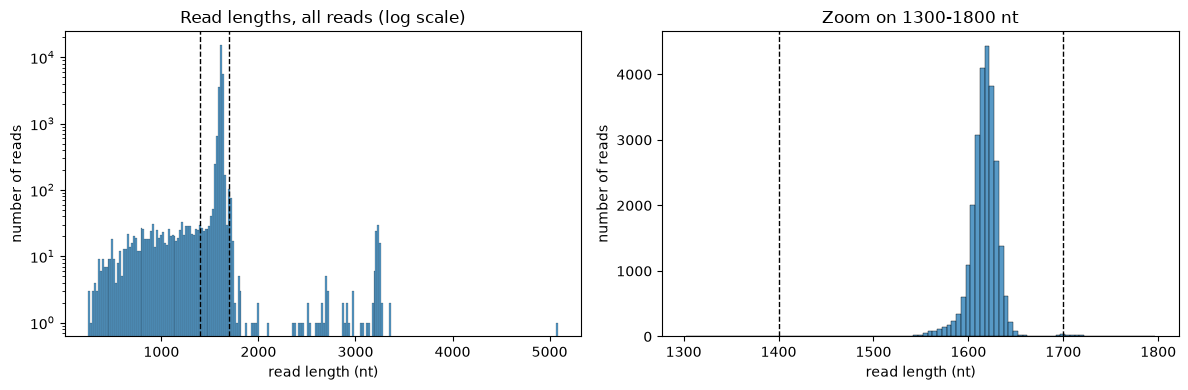

In [38]:
# YOUR CODE

fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(12, 4))

# left: all reads
sns.histplot(lengths, binwidth=20, ax=ax_all)
ax_all.set_yscale("log")   # log scale, otherwise the rare short/long reads are invisible
ax_all.set_title("Read lengths, all reads (log scale)")

# right: zoom on the region around the filter
sns.histplot(lengths[(lengths > 1300) & (lengths < 1800)], binwidth=5, ax=ax_zoom)
ax_zoom.set_title("Zoom on 1300-1800 nt")

for ax in (ax_all, ax_zoom):
    ax.axvline(1400, color="black", linestyle="--", linewidth=1)
    ax.axvline(1700, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("read length (nt)")
    ax.set_ylabel("number of reads")

plt.tight_layout()
plt.show()

In [39]:
# YOUR ANSWERS TO Q3: replace each ... and run the cell
Q3 = {
    "n_filtered": len(filtered),         # number of reads with length between 1400 and 1700 nt
    "why_filter": "The 16S gene is about 1500 bp, so with the primers and adapters a complete read should be around 1500-1650 nt, and in our histogram most reads are indeed between 1560 and 1640 nt. Keeping only this range removes fragments and artefacts that don't cover the whole gene and would give many small, wrong clusters with cd-hit. We keep 25786 of our 27012 reads (about 95%), so we lose very little data.",         # text (max. 3 sentences)
    "short_long_reads": "The short reads (down to 245 nt) are probably DNA molecules that broke during extraction or library preparation, or strands that left the pore before the end was read. The long reads (up to 5086 nt) can be PCR chimeras, or two molecules that went through the same pore right after each other and were called as one read: this fits the small peak we see around 3200 nt, i.e. twice the normal 16S read length.",   # text (max. 3 sentences): how to explain much shorter / longer reads?
}
submit("Q3", Q3)

#ANSWER Q3 {"n_filtered": 25786, "why_filter": "The 16S gene is about 1500 bp, so with the primers and adapters a complete read should be around 1500-1650 nt, and in our histogram most reads are indeed between 1560 and 1640 nt. Keeping only this range removes fragments and artefacts that don't cover the whole gene and would give many small, wrong clusters with cd-hit. We keep 25786 of our 27012 reads (about 95%), so we lose very little data.", "short_long_reads": "The short reads (down to 245 nt) are probably DNA molecules that broke during extraction or library preparation, or strands that left the pore before the end was read. The long reads (up to 5086 nt) can be PCR chimeras, or two molecules that went through the same pore right after each other and were called as one read: this fits the small peak we see around 3200 nt, i.e. twice the normal 16S read length."}


### Assignment 4: Cluster the sequences with CD-hit

Cluster the filtered reads using cd-hit. Then, answer the following questions (more explanations below):

***Questions Q4:***

* How are the cluster sizes distributed? (draw a histogram)
* How large are your largest clusters and how many clusters have size 1?
* How does the clustering change for a different threshold in cd-hit, at 97% identity?

*Runtime:* clustering at 95% takes a few minutes; at 97% it takes about ten times longer (start it early; use `-T 0` to use all CPU cores).


Here is a command that clusters at a threshold of 95% identity:
```cd-hit-est -i input.fasta -o clusters -c 0.95 -n 8 -d 0 -M 0 -T 0```

Run ```cd-hit-est``` to see a description of its parameters.

In [40]:
!cd-hit-est

		====== CD-HIT version 4.8.1 (built on Apr 24 2025) ======

Usage: cd-hit-est [Options] 

Options

   -i	input filename in fasta format, required, can be in .gz format
   -j	input filename in fasta/fastq format for R2 reads if input are paired end (PE) files
 	 -i R1.fq -j R2.fq -o output_R1 -op output_R2 or
 	 -i R1.fa -j R2.fa -o output_R1 -op output_R2 
   -o	output filename, required
   -op	output filename for R2 reads if input are paired end (PE) files
   -c	sequence identity threshold, default 0.9
 	this is the default cd-hit's "global sequence identity" calculated as:
 	number of identical amino acids or bases in alignment
 	divided by the full length of the shorter sequence
   -G	use global sequence identity, default 1
 	if set to 0, then use local sequence identity, calculated as :
 	number of identical amino acids or bases in alignment
 	divided by the length of the alignment
 	NOTE!!! don't use -G 0 unless you use alignment coverage controls
 	see options -aL, -AL, -aS, -AS

In [41]:
# clustering of our filtered reads at 95% identity (takes a few minutes)
!cd-hit-est -i reads_filtered.fasta -o clusters -c 0.95 -n 8 -d 0 -M 0 -T 0 > cdhit_95.log

# same at 97% identity (takes longer)
!cd-hit-est -i reads_filtered.fasta -o clusters_97 -c 0.97 -n 8 -d 0 -M 0 -T 0 > cdhit_97.log

The command writes a fasta file `clusters` of cluster representatives as well as a clustering report `clusters.clstr`. The latter file can be parsed to obtain a
list of lists of the sequence ids in each cluster.

Here is example code to read the cluster report file:

In [42]:
def read_clstr(clstr_file):
    clusters = list()
    with open(clstr_file) as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">Cluster"):
                clusters.append(list())
            else:
                seq_id = line.split(">")[1].split("...")[0]
                clusters[-1].append(seq_id)

    return clusters

clusters = read_clstr("clusters.clstr")

print(len(clusters), "clusters; the first one:", clusters[0])

2651 clusters; the first one: ['6317c29a-5e48-43a0-a7e0-f9361f628c4c', '214d4d07-b679-4eab-bbc9-55d718ec09c0', '28afcdc9-69df-4611-b844-303d2dfe596f', 'f63ddd4f-ed03-464d-b798-1fc07c0ee377', 'dc4c94f9-62ca-486b-9f8b-04d9592c930e', 'dd65517a-015f-4ca9-8bf1-30e9da8dee7e', 'ff491a81-a0c3-447a-bb14-9287733c60ee', '1816af73-6193-4f3e-be13-0be4cf14def6', '05454f1d-6f6c-4b69-adaa-a09e46b2ad96', '35b1d877-d8f1-429d-8ca8-0113fc6e2224', '3de36755-5655-4d0f-a985-5e71b50b96a7', '875e9f24-7a4b-4272-9680-ee62379be4f6', 'd3b61e1a-81c9-4e7b-8b69-500a8863a0be', '8fda7ddc-53ed-4bcb-9f86-a5d92ed4f92a', '1bdbf8fb-8227-45f3-b955-f50149608263', 'e955bbb2-3489-4296-89de-7b2824da2a01', 'a11218b7-f9bb-43cd-9976-58afa8a587fd', '8b5e7c79-82af-4d68-903f-20fc3eb140dc', '985067fb-0662-4cf5-a213-72324c3b8c87', '7095aa77-505f-4d6e-a826-943f2f8e436d', 'ffdc9a19-4467-4c61-abc8-e430bcd6887d', '43ed7821-1019-4cc1-aeb8-d3bdc5352564', '6ea17b04-0d6b-4d42-9019-fba6b28bda9a', '9263ac30-960a-4751-96aa-59aa0a148df9', '3b844dbd

95%: number of clusters: 2651
95%: 5 largest clusters: [4441, 2776, 2260, 2042, 1933]
95%: clusters of size 1: 2520
97%: number of clusters: 9922
97%: 5 largest clusters: [1427, 824, 748, 648, 507]
97%: clusters of size 1: 9488


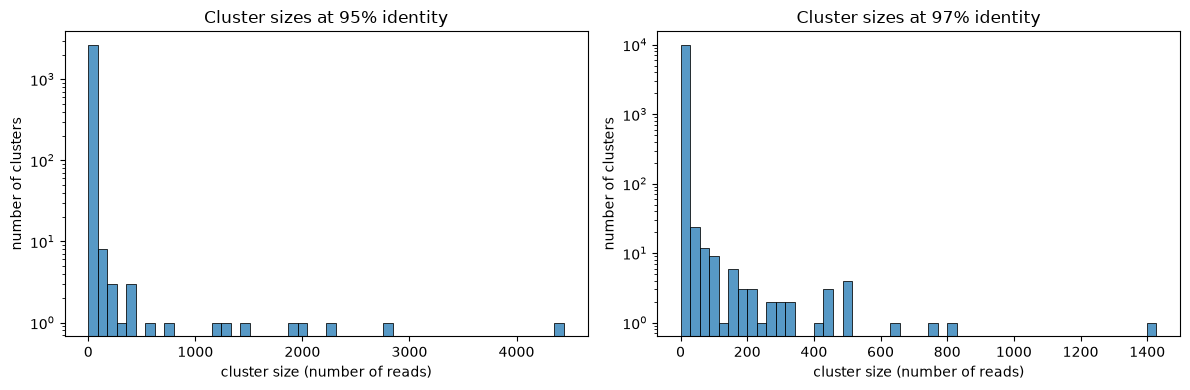

In [43]:
# YOUR CODE

# cluster sizes at 95%, from the largest to the smallest
sizes_95 = sorted([len(c) for c in clusters], reverse=True)
print("95%: number of clusters:", len(sizes_95))
print("95%: 5 largest clusters:", sizes_95[:5])
print("95%: clusters of size 1:", sizes_95.count(1))

# same at 97%
clusters_97 = read_clstr("clusters_97.clstr")
sizes_97 = sorted([len(c) for c in clusters_97], reverse=True)
print("97%: number of clusters:", len(sizes_97))
print("97%: 5 largest clusters:", sizes_97[:5])
print("97%: clusters of size 1:", sizes_97.count(1))

# histograms of the cluster sizes (log scale, otherwise we only see the singletons)
fig, (ax95, ax97) = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(sizes_95, bins=50, ax=ax95)
ax95.set_title("Cluster sizes at 95% identity")
sns.histplot(sizes_97, bins=50, ax=ax97)
ax97.set_title("Cluster sizes at 97% identity")

for ax in (ax95, ax97):
    ax.set_yscale("log")
    ax.set_xlabel("cluster size (number of reads)")
    ax.set_ylabel("number of clusters")

plt.tight_layout()
plt.show()

In [44]:
# YOUR ANSWERS TO Q4: replace each ... and run the cell
Q4 = {
    "n_clusters_95": len(sizes_95),      # number of clusters at 95% identity
    "largest5_95": sizes_95[:5],        # list: sizes of the 5 largest clusters at 95%
    "n_singletons_95": sizes_95.count(1),    # number of clusters of size 1 at 95%
    "n_clusters_97": len(sizes_97),      # same at 97% identity
    "largest5_97": sizes_97[:5],
    "n_singletons_97": sizes_97.count(1),
    "comparison": "At 97% we get almost 4 times more clusters (9922 instead of 2651), the largest clusters are much smaller (1427 reads instead of 4441) and almost all the new clusters are singletons. Our reads have about 3% sequencing errors (Q2), so two reads from the same species can easily differ by more than 3% and are not put together anymore at 97%. For our Nanopore reads 95% works better, because the big clusters stay together, even if two very close species could end up in the same cluster.",         # text (max. 3 sentences): how and why does the clustering change?
}
submit("Q4", Q4)

#ANSWER Q4 {"n_clusters_95": 2651, "largest5_95": [4441, 2776, 2260, 2042, 1933], "n_singletons_95": 2520, "n_clusters_97": 9922, "largest5_97": [1427, 824, 748, 648, 507], "n_singletons_97": 9488, "comparison": "At 97% we get almost 4 times more clusters (9922 instead of 2651), the largest clusters are much smaller (1427 reads instead of 4441) and almost all the new clusters are singletons. Our reads have about 3% sequencing errors (Q2), so two reads from the same species can easily differ by more than 3% and are not put together anymore at 97%. For our Nanopore reads 95% works better, because the big clusters stay together, even if two very close species could end up in the same cluster."}


### Assignment 5: Multiple alignment and phylogenetic tree of the largest cluster

Generate a multiple alignment and phylogenetic tree of the largest cluster (details below). Then, briefly discuss the following questions:

***Questions Q5***
* How much time does it take to align and to build the tree? (Use `%%time` at the top of a cell to measure.)
* How do you interpret the tree? Can you identify subclusters?

Optionally look at the next largest clusters in the same way...

#### Details for Assignment 5
Start by generating a fasta file of all sequences in the largest cluster. From `read_clstr`, we can obtain a list of sequence ids of the sequences in the largest cluster. Here is example code to go through the input file of the clustering and collect all entries in the largest cluster. Here, `largest_cluster_ids` is meant to be a `set` of sequence ids that you need to define yourself (membership tests in sets are fast, in lists they are slow):

In [45]:
# the largest cluster at 95% (clusters comes from read_clstr above)
largest_cluster = max(clusters, key=len)
largest_cluster_ids = set(largest_cluster)   # a set: "in" tests are fast
print("reads in the largest cluster:", len(largest_cluster_ids))

with open("reads_filtered.fasta", "rt") as infh:
    with open("largest_cluster.fasta", "wt") as outfh: 
        for record in SeqIO.parse(infh, "fasta"):
            seq_id=record.id
            if seq_id in largest_cluster_ids:
                SeqIO.write(record,outfh,"fasta")

reads in the largest cluster: 4441


Next, use the alignment tool mafft to align the sequences and write the result to a fasta file. View the multiple alignment using `jalview` (or using some server online).

In [46]:
%%time
# alignment of the largest cluster (several minutes: ~4400 reads)
import time
t0 = time.time()
!mafft --thread 8 --auto largest_cluster.fasta  > largest_cluster_aligned.fasta
time_align = time.time() - t0

nthread = 8
nthreadpair = 8
nthreadtb = 8
ppenalty_ex = 0
stacksize: 8192 kb
generating a scoring matrix for nucleotide (dist=200) ... done
Gap Penalty = -1.53, +0.00, +0.00



Making a distance matrix ..
 4401 / 4441 (thread    5)
done.

Constructing a UPGMA tree (efffree=0) ... 
 4430 / 4441
done.

Progressive alignment 1/2... 
STEP   254 / 4440 (thread    7)
Reallocating..done. *alloclen = 4409
STEP  2001 / 4440 (thread    1)
Reallocating..done. *alloclen = 5511
STEP  3501 / 4440 (thread    6)
Reallocating..done. *alloclen = 6935
STEP  4401 / 4440 (thread    4) h
Reallocating..done. *alloclen = 9667

done.

Making a distance matrix from msa.. 
 4400 / 4441 (thread    5)
done.

Constructing a UPGMA tree (efffree=1) ... 
 4430 / 4441
done.

Progressive alignment 2/2... 
STEP   431 / 4440 (thread    7)
Reallocating..done. *alloclen = 4413
STEP  2201 / 4440 (thread    7)
Reallocating..done. *alloclen = 5422
STEP  3701 / 4440 (thread    7)
Reallocating..done. *alloclen = 6472
STEP  4401 

Finally use FastTree to produce a phylogenetic tree from the alignment.
The results are written in NEWICK format, a string representation of a tree, to the file largest_cluster_tree.nwk.

View the phylogenetic tree online at https://itol.embl.de/upload.cgi
The server allows you to upload the produced newick file.

FastTree can be used in the following way (call `FastTree` without arguments to learn about the possible arguments):

In [47]:
%%time
# tree from the alignment (fast: no maximum-likelihood step with -noml)
t0 = time.time()
!FastTree -noml -nt largest_cluster_aligned.fasta > largest_cluster_tree.nwk
time_tree = time.time() - t0

FastTree Version 2.2.0 Double precision
Alignment: largest_cluster_aligned.fasta
Nucleotide distances: Jukes-Cantor Joins: balanced Support: Local boot 1000
Search: Normal +NNI +SPR (2 rounds range 10) (no ML-NNI)
TopHits: 1.00*sqrtN close=default refresh=0.80
Initial topology in 84.09 seconds of   4438    1 of   4441 seqs   4400)   
Refining topology: 48 rounds ME-NNIs, 2 rounds ME-SPRs, 0 rounds ML-NNIs
Total branch-length 54.376 after 232.98 sec201 of 4439 splits, 7 changes (max delta 0.000)      
Total time: 380.03 seconds Unique: 4441/4441 Bad splits: 7/4438 Worst delta-Len 0.000
CPU times: user 4.13 s, sys: 2.01 s, total: 6.14 s
Wall time: 6min 29s


In [48]:
# A tree with ~4400 leaves is unreadable as a picture, so we look at its first levels:
# for each big clade, its number of reads and the length of the branch leading to it.
# A big clade at the end of a long branch = a group of reads clearly different from the others = a subcluster.
import sys
from Bio import Phylo
sys.setrecursionlimit(100000)   # the tree is deep, Biopython walks it recursively

tree = Phylo.read("largest_cluster_tree.nwk", "newick")
tree.root_at_midpoint()          # FastTree gives an unrooted tree; we root it in the middle of the longest path
print("leaves in the tree:", tree.count_terminals())

def show(clade, depth=0, max_depth=4, min_size=100):
    n = clade.count_terminals()
    if n < min_size or depth > max_depth:
        return
    print("    " * depth + f"clade of {n} reads, branch length {clade.branch_length or 0:.3f}")
    for child in clade.clades:
        show(child, depth + 1, max_depth, min_size)

show(tree.root)

leaves in the tree: 4441
clade of 4441 reads, branch length 0.000
    clade of 2223 reads, branch length 0.048
        clade of 2222 reads, branch length 0.003
            clade of 2221 reads, branch length 0.002
                clade of 2220 reads, branch length 0.001
    clade of 2218 reads, branch length 0.057
        clade of 2217 reads, branch length 0.003
            clade of 2216 reads, branch length 0.001
                clade of 2208 reads, branch length 0.000


In [ ]:
# Why two halves of the same size? cd-hit-est compares reads on both strands: in clusters.clstr,
# "at +" / "at -" gives the orientation of each read. We count the orientations in each half of the tree.
from collections import Counter

strand = {}
with open("clusters.clstr") as fh:
    for line in fh:
        if line.startswith(">"):
            continue
        read_id = line.split(">")[1].split("...")[0]
        if read_id in largest_cluster_ids:
            strand[read_id] = "-" if "at -" in line else "+"   # the representative (*) is + by definition

for half in tree.root.clades:
    print(half.count_terminals(), "reads:", Counter(strand[leaf.name] for leaf in half.get_terminals()))

In [ ]:
# YOUR ANSWERS TO Q5: replace each ... and run the cell
Q5 = {
    "n_sequences": len(largest_cluster_ids),        # number of sequences in the largest cluster (at 95%)
    "time_align_s": round(time_align, 1),       # wall time of mafft in seconds
    "time_tree_s": round(time_tree, 1),        # wall time of FastTree in seconds
    "tree_interpretation": "The tree splits into two halves of almost the same size (2223 and 2218 reads) separated by long branches, but this is not biological: the two halves are exactly the reads sequenced on the + strand and on the - strand (cd-hit-est compares both strands, but mafft aligned them without reverse-complementing). Inside each half all branches are very short (0.003 or less), so we see no real subclusters. The small differences between reads are Nanopore sequencing errors (about 3%, see Q2), so the largest cluster most likely contains one single organism. This artefact could be avoided with mafft --adjustdirection.", # text (max. 4 sentences): how do you interpret the tree? subclusters?
}
submit("Q5", Q5)

### Assignment 6: Identify some organisms

Choose reads from your largest cluster(s), e.g. the representative sequence and some other ones, and find known similar (homologous) sequences using BLAST on the NCBI Blast server:

https://blast.ncbi.nlm.nih.gov/Blast.cgi?PROGRAM=blastn&PAGE_TYPE=BlastSearch&LINK_LOC=blasthome


CAREFUL: Select the rRNA/ITS databases and choose
16S ribosomal RNA sequences (Bacteria and Archaea) from the menu.

*Alternatively*, you can run BLAST locally on your computer against the same NCBI 16S database (see the optional section *Local BLAST* below).

***Questions Q6***:
* How can the phylogenetic tree of the cluster help to select candidate sequences for BLAST?
* Which organisms do you identify according to the best BLAST hits?
* How clearly can the organism be identified? Compare scores and E-values!


Optionally, identify some more organisms from either the best cluster or the next largest ones.

#### Optional: Local BLAST

Instead of the web server, you can install BLAST in your conda environment, download NCBI's 16S rRNA database once, and run `blastn` from the notebook.

| | NCBI web server | local BLAST |
|---|---|---|
| setup | none | `conda install blast` + one-time database download |
| many queries | one by one, by hand (limits on NCBI usage) | many reads in one run (e.g. all cluster representatives) |
| reproducibility | results live on a web page; database is updated without notice | command, parameters and database version are in your notebook |
| output | graphical, with links to taxonomy and records | text/table; you parse it in Python |
| speed | queue at NCBI | fast for a small database like 16S |

Note: both default to `megablast` (word size 28) for nucleotide queries; use `-task blastn` for more sensitive searches.

Download and extract the database (once):

In [ ]:
RUN_LOCAL_BLAST = True    # set to True if you use local BLAST

if RUN_LOCAL_BLAST:
    import os
    os.makedirs("blastdb", exist_ok=True)
    # update_blastdb.pl comes with BLAST from conda (conda install blast)
    !cd blastdb && update_blastdb.pl --decompress 16S_ribosomal_RNA

Then BLAST a fasta file of query sequences (e.g. the cluster representatives written by cd-hit to `clusters`, or a few reads of the largest cluster). The tabular output format (`-outfmt 6`) is easy to read with pandas; `stitle` adds the description of the hit:

In [ ]:
# Queries for BLAST:
# - the representative of each of the 5 largest clusters (cd-hit wrote them in the file "clusters")
# - one read from each half of the tree of the largest cluster (Q5)
top5 = sorted(clusters, key=len, reverse=True)[:5]
cluster_size = {read_id: len(c) for c in top5 for read_id in c}   # read id -> size of its cluster

representatives = [r for r in SeqIO.parse("clusters", "fasta") if r.id in cluster_size]
tree_picks = {half.get_terminals()[0].name for half in tree.root.clades}
picked_reads = [r for r in SeqIO.parse("largest_cluster.fasta", "fasta") if r.id in tree_picks]

SeqIO.write(representatives + picked_reads, "queries.fasta", "fasta")

In [ ]:
import pandas as pd

if RUN_LOCAL_BLAST:
    !blastn -query queries.fasta -db blastdb/16S_ribosomal_RNA -max_target_seqs 5 -outfmt "6 qseqid sacc stitle pident length evalue bitscore" -out blast_hits.tsv

    hits = pd.read_csv("blast_hits.tsv", sep="\t", header=None,
                       names=["query", "accession", "title", "pident", "length", "evalue", "bitscore"])
    display(hits)

In [ ]:
# best hit of each query = its first line (BLAST sorts hits from the best to the worst)
best = hits.drop_duplicates("query").copy()
best["species"] = best["title"].str.split().str[:2].str.join(" ")   # "Genus species"
best["cluster_size"] = best["query"].map(cluster_size)
best[["query", "cluster_size", "species", "pident", "evalue", "bitscore"]]

In [ ]:
# YOUR ANSWERS TO Q6: replace each ... and run the cell
# One entry per read you BLASTed (add or remove entries as needed); report the best hit.
Q6 = {
    "hits": [
        {"read_id": r.query, "cluster_size": int(r.cluster_size), "species": r.species,
         "identity_percent": round(r.pident, 1), "evalue": r.evalue}
        for r in best.itertuples()
    ],
    "tree_helps": "Instead of BLASTing all 4441 reads, the tree shows which reads are similar: we take one read per big clade (here one from each half of the tree) plus the cd-hit representative. Reads from the same clade should give the same organism, so if one clade gave another species it would be a real subcluster. Here both halves give Staphylococcus, which confirms that the split is only the read orientation.",         # text (max. 3 sentences): how can the tree help to select reads for BLAST?
    "how_clear": "All best hits have an E-value of 0 and 97-99% identity over about 1500 nt, so the genus is identified without doubt: Staphylococcus, Listeria, Escherichia/Shigella, Bacillus and Enterococcus. But the 5 best hits of a read are often different species of the same genus with almost the same bit score (e.g. 2654 for S. roterodami vs 2643 for S. aureus), so the species cannot be decided with 16S and ~3% Nanopore errors (E. coli and Shigella even have nearly identical 16S). Enterococcus faecalis is the clearest case: its 4 best hits are all E. faecalis and the next species is much lower (96.3%).",          # text (max. 3 sentences): how clearly are organisms identified (scores, E-values)?
}
submit("Q6", Q6)